# BUSCO: eukaryota (Annotrieve) vs lineage specific (local runs)

1. define the core set of annotations (one per species and group, highest eukaryota BUSCO complete, ties ranked by ID) and save it in `core_annotations.tsv`
2. generate the `run_busco.py` commands for the core annotations that have no lineage specific result yet
3. read the results of the runs and build the long table
4. build the figures from the table in `figures/`

Everything after step 1 reads the core set from the saved file, so the analysis does not change if the Annotrieve API changes.

In [1]:
import io
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path


API = "https://genome.crg.es/annotrieve/api/v0"
LINEAGES_DIR = Path("/no_backup/rg/references/busco_downloads/lineages")
RESULTS_DIR = Path("results")
FIGURES_DIR = Path("figures")
COMMANDS_FILE = Path("run_busco_commands.txt")
COMMANDS_SCOPE = "all"  # "all": a command for every core annotation, "missing": only for those without a lineage specific result in RESULTS_DIR
OUT_TABLE = Path("busco_specifc_VS_generic.tsv")
CORE_FILE = Path("core_annotations.tsv")  # core set of annotations, written once and read by all the following cells
REBUILD_CORE = False  # True: query the API again and overwrite CORE_FILE
RESULTS_DIR.mkdir(exist_ok=True)
FIGURES_DIR.mkdir(exist_ok=True)

# taxonomic groups of interest (taxids resolved with the Annotrieve /taxons endpoint)
GROUPS = {
    "Mammalia": 40674,
    "Primates": 9443,
    "Papilionoidea": 37572,
    "Solanaceae": 4070,
    "Saccharomyces": 4930,
}

# closest available odb12 lineage of each group
LINEAGE = {
    "Mammalia": "mammalia_odb12",
    "Primates": "primates_odb12",
    "Papilionoidea": "papilionoidea_odb12",
    "Solanaceae": "solanales_odb12",
    "Saccharomyces": "saccharomycetes_odb12",
}
GENERIC = "eukaryota_odb12"  # generic BUSCO set, computed by Annotrieve for every annotation
CLASSES = ["complete", "single", "duplicated", "fragmented", "missing"]


def save_figure(fig, name):
    """Save a figure in figures/ as png."""
    fig.savefig(FIGURES_DIR / f"{name}.png", dpi=300, bbox_inches="tight")

## 1. Define the core set of annotations

In [2]:
# use annotrieve API to check the annotation and unique species counts of the selected groups
def species_name(organism_name):
    """Species = genus + epithet, so strains/isolates with their own taxid collapse into their species."""
    return organism_name.str.split().str[:2].str.join(" ")

rows = []
for name, taxid in GROUPS.items():
    t = requests.get(f"{API}/taxons/{taxid}", timeout=60)
    t.raise_for_status()
    t = t.json()
    resp = requests.post(f"{API}/annotations/report", json={"taxids": str(taxid)}, timeout=300)
    resp.raise_for_status()
    report = pd.read_csv(io.StringIO(resp.text), sep="\t")
    rows.append((taxid, t["scientific_name"], t["rank"], t["annotations_count"],
                 species_name(report["organism_name"]).nunique()))

groups = pd.DataFrame(rows, columns=["taxid", "taxon_name", "rank", "annotations_count", "species_count"])
groups

,taxid,taxon_name,rank,annotations_count,species_count
0,40674,Mammalia,class,2383,766
1,9443,Primates,order,779,126
2,37572,Papilionoidea,superfamily,365,210
3,4070,Solanaceae,family,48,31
4,4930,Saccharomyces,genus,541,8


In [3]:
# define the core set: one annotation per species for each group, the one with the highest eukaryota BUSCO complete, ties ranked by annotation_id
# the set is saved with the metadata of the Annotrieve report and all the following cells read it from CORE_FILE
BUSCO_FIELDS = "busco_lineage,busco_total_count,busco_complete,busco_single_copy,busco_duplicated,busco_fragmented,busco_missing"

def fetch_busco(taxid):
    """All annotations of a taxon that have a BUSCO complete value, with all the BUSCO classes."""
    body = {
        "taxids": str(taxid),
        "busco_complete_from": 0,
        "selected_fields": BUSCO_FIELDS,
    }
    resp = requests.post(f"{API}/annotations/report", json=body, timeout=300)
    resp.raise_for_status()
    df = pd.read_csv(io.StringIO(resp.text), sep="\t")
    return df.dropna(subset=["busco_complete"])

if REBUILD_CORE or not CORE_FILE.exists():
    counts = groups.set_index("taxid")
    selected = []
    for group, taxid in GROUPS.items():
        df = fetch_busco(taxid)
        n_annotations = len(df)
        df = df.assign(species=species_name(df["organism_name"]))
        df = (
            df.sort_values(["busco_complete", "annotation_id"], ascending=[False, False])
            .drop_duplicates("species")
            .assign(group=group)
        )
        print(f"{group}: {len(df)} species with BUSCO of {counts.loc[taxid, 'species_count']} "
              f"({n_annotations} annotations with BUSCO of {counts.loc[taxid, 'annotations_count']})")
        selected.append(df)

    core = pd.concat(selected, ignore_index=True)
    assert (core["busco_lineage"] == GENERIC).all(), "unexpected BUSCO lineage in the Annotrieve values"
    core = core[["group", "species"] + [col for col in core.columns if col not in ("group", "species")]]
    core.to_csv(CORE_FILE, sep="\t", index=False)
    print(f"core set of {len(core)} annotations saved to {CORE_FILE}")
else:
    print(f"{CORE_FILE} already exists, not rebuilt (set REBUILD_CORE = True to rebuild it)")


core_annotations.tsv already exists, not rebuilt (set REBUILD_CORE = True to rebuild it)


In [4]:
# read the core set: from here on all the cells use this table
core = pd.read_csv(CORE_FILE, sep="\t")
print(f"{len(core)} annotations in the core set")
print(core.groupby("group").size().reindex(list(GROUPS)).to_string())
core.head()

1082 annotations in the core set
group
Mammalia         712
Primates         125
Papilionoidea    208
Solanaceae        29
Saccharomyces      8


,group,species,annotation_id,assembly_accession,assembly_name,organism_name,taxid,database,provider,source_url,bgzip_path,csi_path,busco_lineage,busco_total_count,busco_complete,busco_single_copy,busco_duplicated,busco_fragmented,busco_missing
0,Mammalia,Mesoplodon bidens,fe2ae9575aa91be72e1727e22598f843,GCF_964165515.1,mMesBid2.hap1.1,Mesoplodon bidens,48745,RefSeq,Vertebrate Genome Laboratory,https://ftp.ncbi.nlm.nih.gov/genomes/all/GCF/9...,/48745/GCF_964165515.1/RefSeq_882d4ef11b8d87e1...,/48745/GCF_964165515.1/RefSeq_882d4ef11b8d87e1...,eukaryota_odb12,129,100.0,89.9,10.1,0.0,0.0
1,Mammalia,Aethalodelphis obliquidens,f893d598681302e2ee1237b826e9acc2,GCF_003676395.1,ASM367639v1,Aethalodelphis obliquidens,3371155,RefSeq,NCBI RefSeq,https://ftp.ncbi.nlm.nih.gov/genomes/all/GCF/0...,/3371155/GCF_003676395.1/RefSeq_0a55732f431066...,/3371155/GCF_003676395.1/RefSeq_0a55732f431066...,eukaryota_odb12,129,100.0,97.7,2.3,0.0,0.0
2,Mammalia,Leucopleurus acutus,f36f4230097dea820ba8221f94e65553,GCF_964270905.1,mLagAcu1.hap1.1,Leucopleurus acutus,3371109,RefSeq,Vertebrate Genome Laboratory,https://ftp.ncbi.nlm.nih.gov/genomes/all/GCF/9...,/3371109/GCF_964270905.1/RefSeq_9207a1576aeaca...,/3371109/GCF_964270905.1/RefSeq_9207a1576aeaca...,eukaryota_odb12,129,100.0,98.4,1.6,0.0,0.0
3,Mammalia,Mesoplodon mirus,f0c5720241e74b10341aaeaacc863198,GCF_964341445.2,mMesMir1.hap1.2,Mesoplodon mirus,52113,RefSeq,Vertebrate Genome Laboratory,https://ftp.ncbi.nlm.nih.gov/genomes/all/GCF/9...,/52113/GCF_964341445.2/RefSeq_40908401d728fa89...,/52113/GCF_964341445.2/RefSeq_40908401d728fa89...,eukaryota_odb12,129,100.0,91.5,8.5,0.0,0.0
4,Mammalia,Canis lupus,f059d7e2761c8bc24eb298d1aa5cbb83,GCF_011100685.1,UU_Cfam_GSD_1.0,Canis lupus familiaris,9615,RefSeq,NCBI RefSeq,https://ftp.ncbi.nlm.nih.gov/genomes/all/GCF/0...,/9615/GCF_011100685.1/RefSeq_e5fca6c136276066f...,/9615/GCF_011100685.1/RefSeq_e5fca6c136276066f...,eukaryota_odb12,129,100.0,93.8,6.2,0.0,0.0


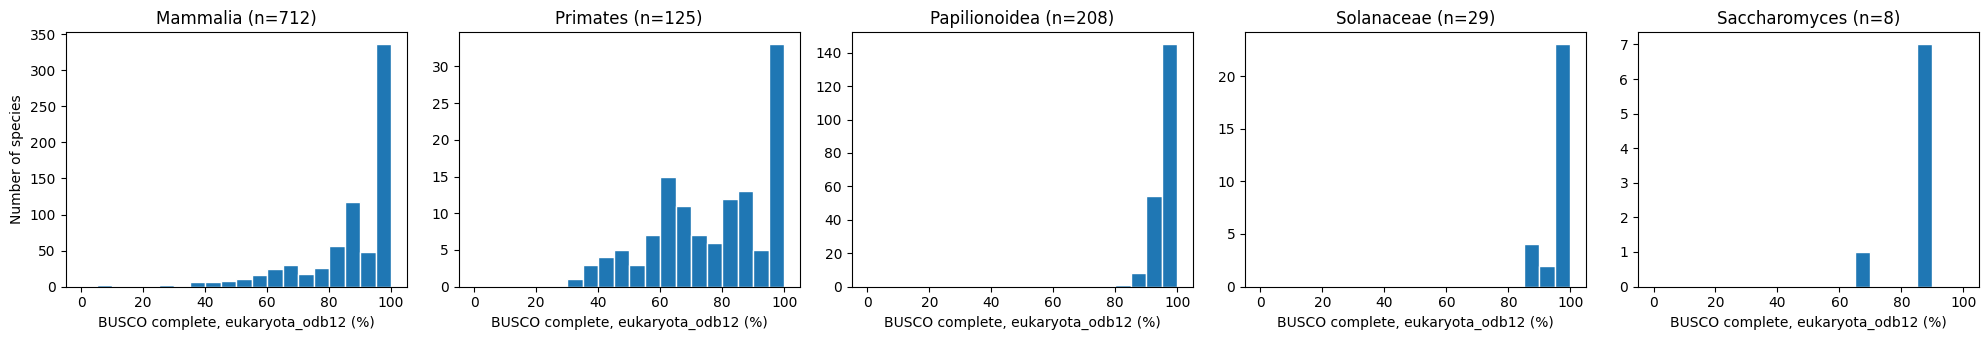

In [5]:
# plot complete percentage BUSCO values distribution in 5 panes using histograms, one per group with one value per species
fig, axes = plt.subplots(1, len(GROUPS), figsize=(4 * len(GROUPS), 3.5), sharex=True)
bins = range(0, 101, 5)

for ax, group in zip(axes, GROUPS):
    vals = core.loc[core["group"] == group, "busco_complete"]
    ax.hist(vals, bins=bins, edgecolor="white")
    ax.set_title(f"{group} (n={len(vals)})")
    ax.set_xlabel(f"BUSCO complete, {GENERIC} (%)")

axes[0].set_ylabel("Number of species")
fig.tight_layout()
save_figure(fig, "eukaryota_complete_histogram_by_group")
plt.show()

## 2. Generate the commands

In [6]:
# generate a txt file with one run_busco.py command per core annotation (COMMANDS_SCOPE = "all") or only per core annotation without a lineage specific result (COMMANDS_SCOPE = "missing"), using the BUSCO lineage of each group
# the results of run_busco.py are written to results/<annotation_id>_<lineage>/BUSCO_<annotation_id>.tsv
assert COMMANDS_SCOPE in ("all", "missing"), 'COMMANDS_SCOPE must be "all" or "missing"'
ACTIVATE_ENV = "source ~/miniconda3/etc/profile.d/conda.sh && conda activate busco-annotrieve"

def result_file(annotation_id, lineage):
    return RESULTS_DIR / f"{annotation_id}_{lineage}" / f"BUSCO_{annotation_id}.tsv"

n_done = n_commands = 0
with open(COMMANDS_FILE, "w") as f:
    for group, lineage in LINEAGE.items():
        lineage_path = LINEAGES_DIR / lineage
        assert lineage_path.is_dir(), f"missing lineage {lineage_path}"
        for annotation_id in core.loc[core["group"] == group, "annotation_id"]:
            done = result_file(annotation_id, lineage).exists()
            n_done += done
            if COMMANDS_SCOPE == "missing" and done:
                continue
            n_commands += 1
            f.write(f"{ACTIVATE_ENV} && python run_busco.py {annotation_id} {lineage_path} --cpu 4 -o results/{annotation_id} \n")

print(f"{n_done} of {len(core)} core annotations already have the lineage specific BUSCO; "
      f"{n_commands} commands ({COMMANDS_SCOPE}) written to {COMMANDS_FILE}")


1059 of 1082 core annotations already have the lineage specific BUSCO; 1082 commands (all) written to run_busco_commands.txt


## 3. Read the results and build the table

In [7]:
# read the lineage specific results from the /results folder and keep, for each annotation, only the group whose lineage it used
specific = pd.concat(
    [pd.read_csv(f, sep="\t") for f in sorted(RESULTS_DIR.glob("*/BUSCO_*.tsv"))],
    ignore_index=True,
)
# an annotation can belong to several (nested) groups: keep each result only for the group whose lineage it used
specific = (
    core[["group", "species", "annotation_id"]]
    .merge(specific, on="annotation_id", how="inner")
    .assign(group_lineage=lambda d: d["group"].map(LINEAGE))
    .query("lineage == group_lineage")
    .drop(columns="group_lineage")
)
print(f"{len(specific)} annotations with lineage specific BUSCO of {len(core)} selected")
print(specific.groupby("group").size().to_string())

1059 annotations with lineage specific BUSCO of 1082 selected
group
Mammalia         710
Papilionoidea    189
Primates         123
Saccharomyces      8
Solanaceae        29


In [8]:
# long table: one row per annotation x BUSCO db x BUSCO class, with the eukaryota values (Annotrieve API) and the lineage specific ones (local runs)
ID_COLS = ["species", "annotation_id", "lineage", "busco_db", "busco_count"]
# lineage: key of the LINEAGE dictionary (the group), busco_db: its value (the BUSCO database)

# lineage specific: from the local BUSCO runs
spec = specific.rename(columns={"group": "lineage", "lineage": "busco_db"})

# eukaryota: from the Annotrieve API, same annotations as the lineage specific ones
euk = specific[["group", "species", "annotation_id"]].merge(
    core[["group", "annotation_id", "busco_lineage", "busco_total_count", "busco_complete",
           "busco_single_copy", "busco_duplicated", "busco_fragmented", "busco_missing"]],
    on=["group", "annotation_id"],
    how="inner",
).rename(columns={
    "group": "lineage", "busco_lineage": "busco_db", "busco_total_count": "busco_count", "busco_complete": "complete",
    "busco_single_copy": "single", "busco_duplicated": "duplicated",
    "busco_fragmented": "fragmented", "busco_missing": "missing",
})

busco_long = (
    pd.concat([euk, spec], ignore_index=True)
    .melt(id_vars=ID_COLS, value_vars=CLASSES, var_name="busco_class", value_name="percentage")
    .sort_values(["species", "annotation_id", "lineage", "busco_db"], kind="stable")
    .reset_index(drop=True)
)
busco_long.to_csv(OUT_TABLE, sep="\t", index=False)
print(f"{busco_long['annotation_id'].nunique()} annotations, {busco_long['busco_db'].nunique()} BUSCO dbs, "
      f"{len(busco_long)} rows saved to {OUT_TABLE}")
busco_long.head(10)

936 annotations, 6 BUSCO dbs, 10590 rows saved to busco_specifc_VS_generic.tsv


,species,annotation_id,lineage,busco_db,busco_count,busco_class,percentage
0,Acinonyx jubatus,a85f47526b4f957991edd08aa7d47c25,Mammalia,eukaryota_odb12,129,complete,100.0
1,Acinonyx jubatus,a85f47526b4f957991edd08aa7d47c25,Mammalia,eukaryota_odb12,129,single,96.9
2,Acinonyx jubatus,a85f47526b4f957991edd08aa7d47c25,Mammalia,eukaryota_odb12,129,duplicated,3.1
3,Acinonyx jubatus,a85f47526b4f957991edd08aa7d47c25,Mammalia,eukaryota_odb12,129,fragmented,0.0
4,Acinonyx jubatus,a85f47526b4f957991edd08aa7d47c25,Mammalia,eukaryota_odb12,129,missing,0.0
5,Acinonyx jubatus,a85f47526b4f957991edd08aa7d47c25,Mammalia,mammalia_odb12,12277,complete,98.8
6,Acinonyx jubatus,a85f47526b4f957991edd08aa7d47c25,Mammalia,mammalia_odb12,12277,single,98.6
7,Acinonyx jubatus,a85f47526b4f957991edd08aa7d47c25,Mammalia,mammalia_odb12,12277,duplicated,0.2
8,Acinonyx jubatus,a85f47526b4f957991edd08aa7d47c25,Mammalia,mammalia_odb12,12277,fragmented,0.6
9,Acinonyx jubatus,a85f47526b4f957991edd08aa7d47c25,Mammalia,mammalia_odb12,12277,missing,0.6


## 4. Figures from the table

In [9]:
# one row per annotation with the complete percentage of the eukaryota and of the lineage specific BUSCO, taken from the table
complete = busco_long[busco_long["busco_class"] == "complete"]
keys = ["species", "annotation_id", "lineage"]
comparison = (
    complete[complete["busco_db"] == GENERIC].set_index(keys)["percentage"].rename("busco_complete_eukaryota").to_frame()
    .join(complete[complete["busco_db"] == complete["lineage"].map(LINEAGE)].set_index(keys)["percentage"].rename("busco_complete_specific"))
    .reset_index()
    .assign(group=lambda d: d["lineage"])
)
groups_in_table = [g for g in list(GROUPS) if g in set(comparison["group"])]
comparison.head()

,species,annotation_id,lineage,busco_complete_eukaryota,busco_complete_specific,group
0,Acinonyx jubatus,a85f47526b4f957991edd08aa7d47c25,Mammalia,100.0,98.8,Mammalia
1,Acomys cahirinus,b1864a752dab231a0f4f938e832a6dd7,Mammalia,96.9,97.7,Mammalia
2,Acomys dimidiatus,bfe4e291766fe73bb4d4083d0962b750,Mammalia,98.4,95.0,Mammalia
3,Acomys kempi,5bd834b3660db879ffb10d07e1d3dbf2,Mammalia,98.4,96.1,Mammalia
4,Acomys minous,e94f9561e94ed9af5e274997aacf1160,Mammalia,99.2,98.8,Mammalia


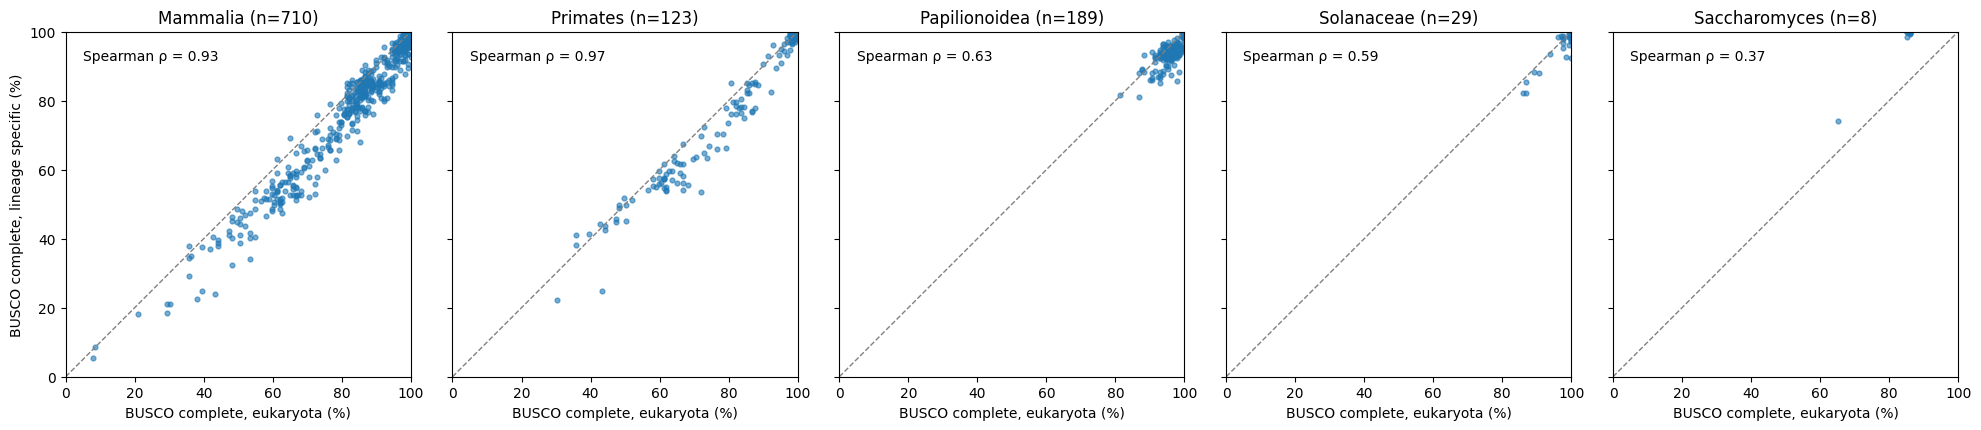

In [10]:
# generate a plot with five panes and a scatter plot to compare the lineage specific value and the eukariotic generic value
fig, axes = plt.subplots(1, len(groups_in_table), figsize=(4 * len(groups_in_table), 4), sharex=True, sharey=True, squeeze=False)
axes = axes[0]

for ax, group in zip(axes, groups_in_table):
    df = comparison[comparison["group"] == group]
    ax.scatter(df["busco_complete_eukaryota"], df["busco_complete_specific"], s=12, alpha=0.6)
    ax.plot([0, 100], [0, 100], color="grey", linestyle="--", linewidth=1)  # y = x
    ax.set_title(f"{group} (n={len(df)})")
    ax.set_xlabel("BUSCO complete, eukaryota (%)")
    ax.set_xlim(0, 100)
    ax.set_ylim(0, 100)
    ax.set_aspect("equal")
    rho = df["busco_complete_eukaryota"].corr(df["busco_complete_specific"], method="spearman")
    label = f"Spearman \u03c1 = {rho:.2f}" if len(df) >= 3 and pd.notna(rho) else "Spearman \u03c1 = n/a (n < 3)"
    ax.text(0.05, 0.95, label, transform=ax.transAxes, va="top")

axes[0].set_ylabel("BUSCO complete, lineage specific (%)")
fig.tight_layout()
save_figure(fig, "scatter_eukaryota_vs_specific")
plt.show()

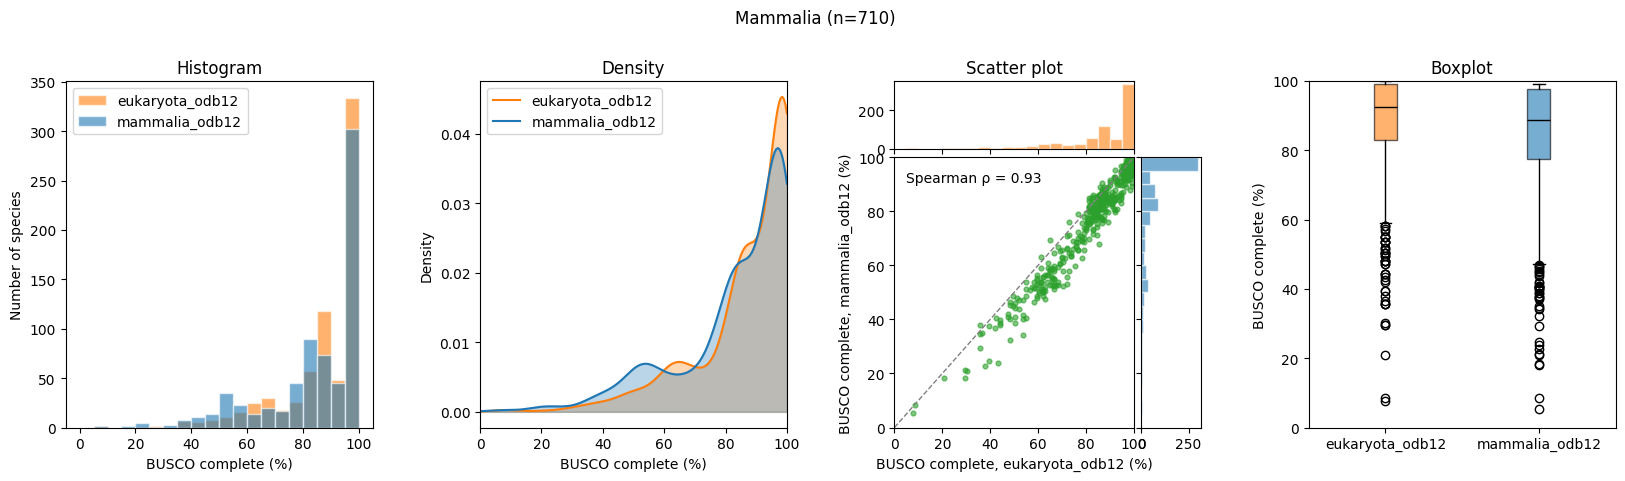

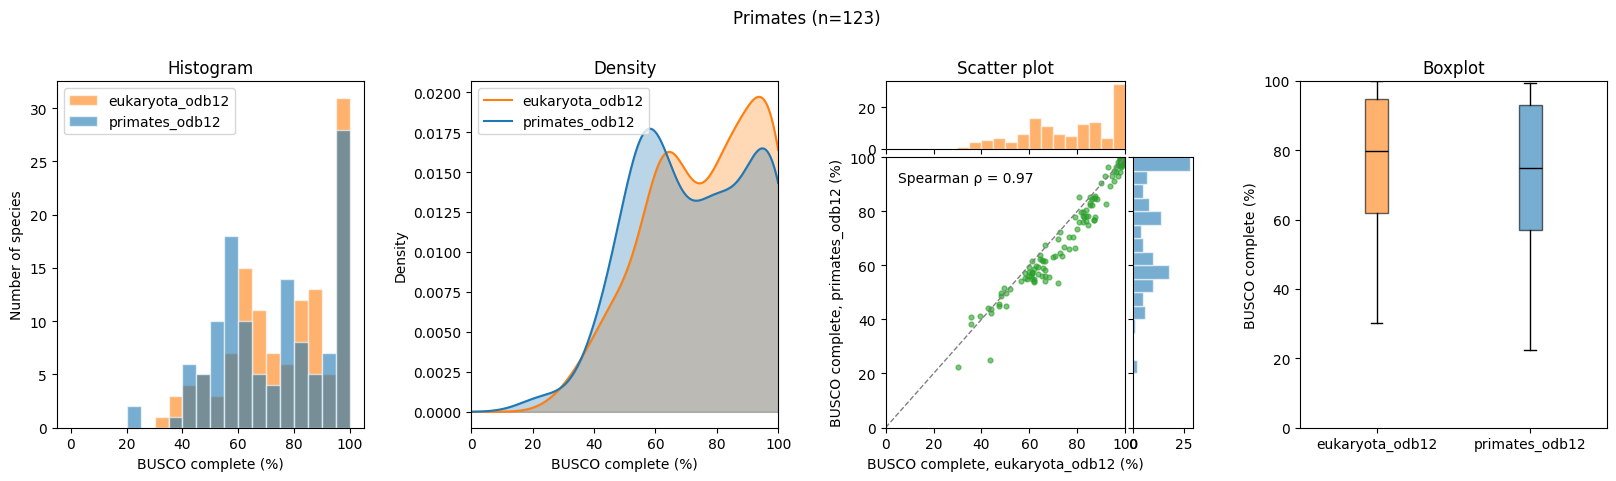

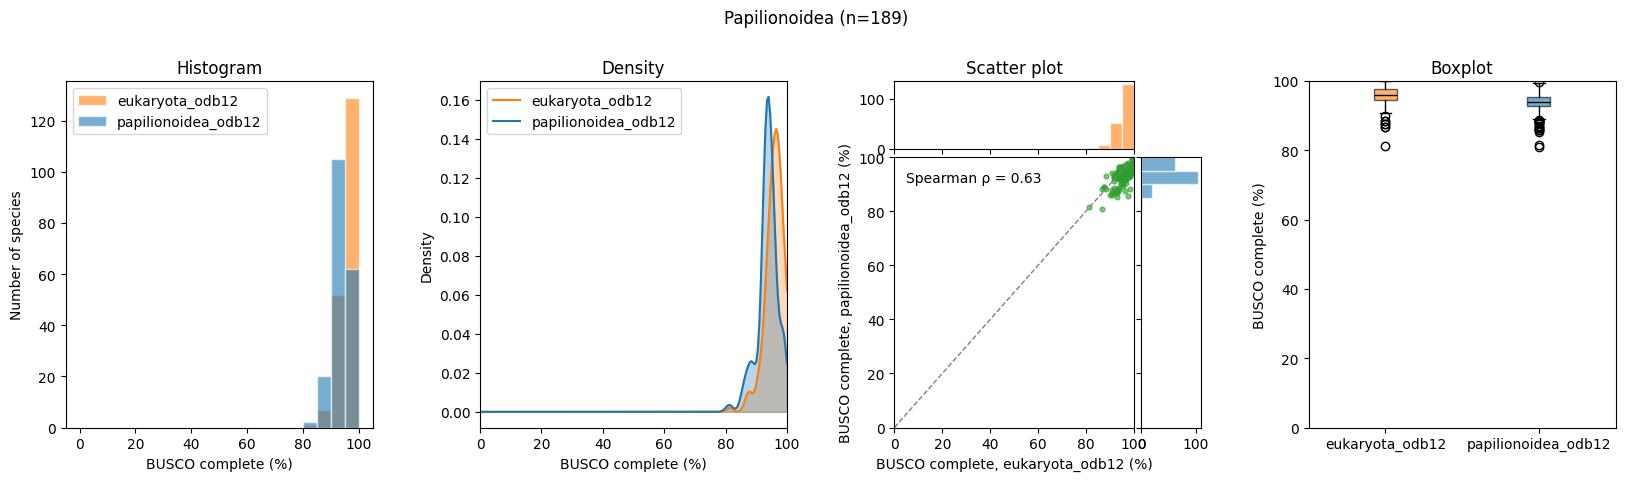

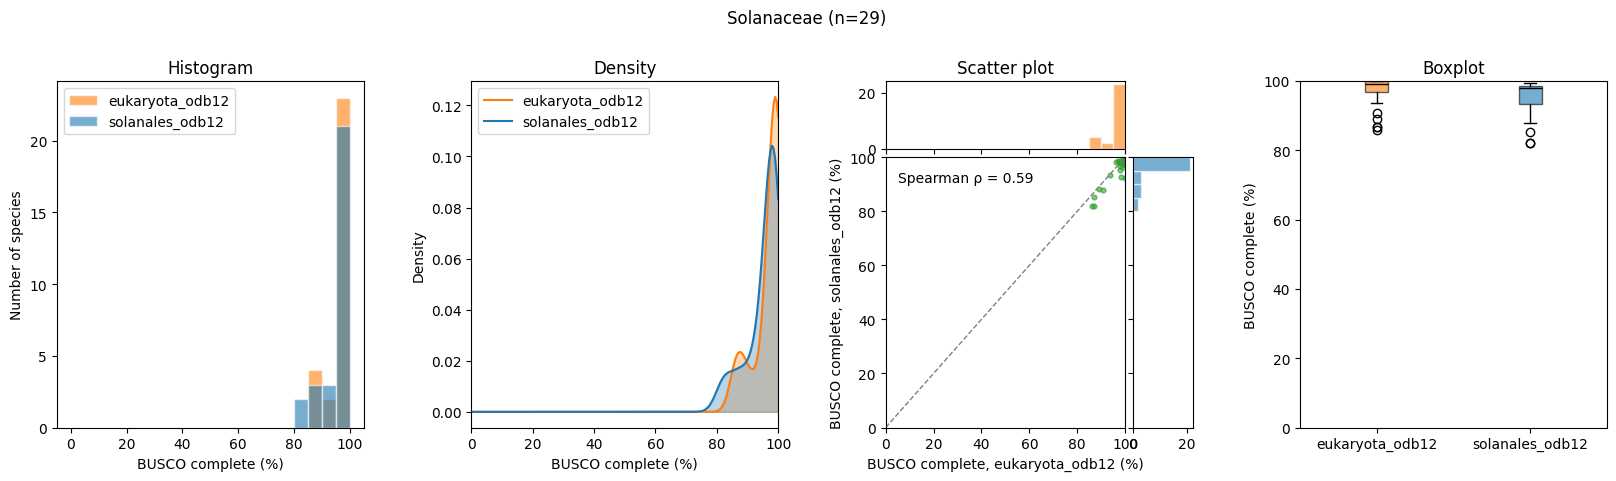

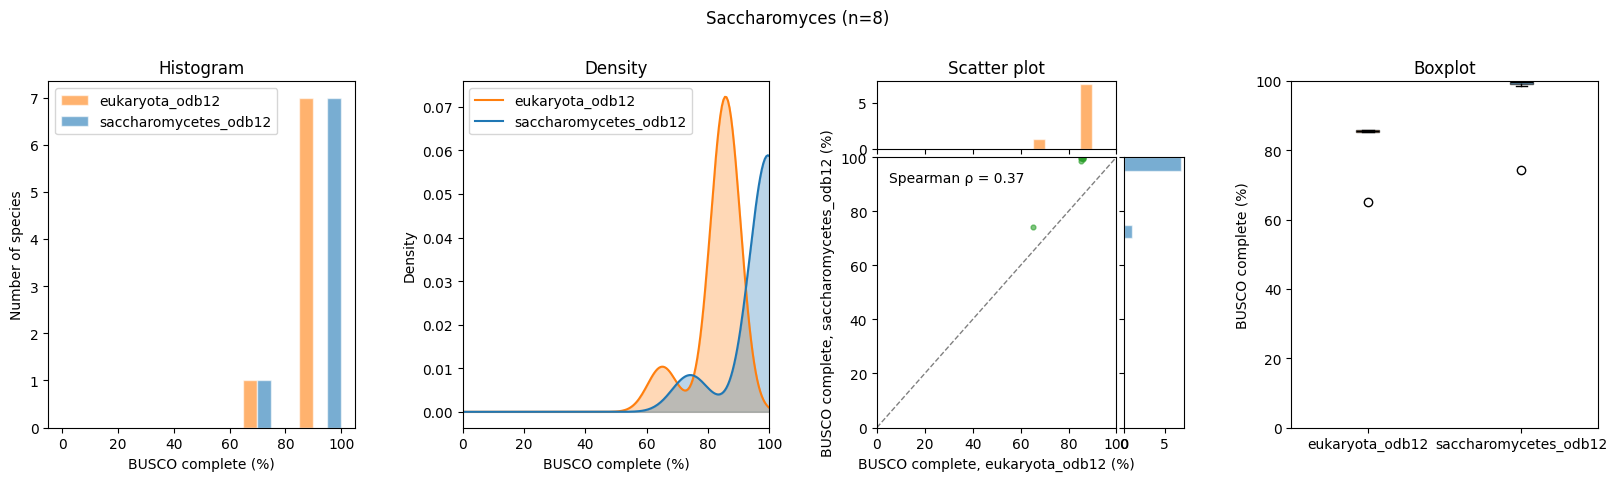

In [11]:
# plot the busco of each group as histograms, density, scatter with marginal histograms and boxplot
grid = np.linspace(0, 100, 201)
bins = range(0, 101, 5)


def kde(x, grid):
    """Gaussian kernel density estimate of x on grid (Scott's rule bandwidth)."""
    h = x.std(ddof=1) * len(x) ** (-1 / 5)
    z = (grid[:, None] - x[None, :]) / h
    return np.exp(-0.5 * z**2).sum(axis=1) / (len(x) * h * np.sqrt(2 * np.pi))


def plot_group(group, lineage, comparison):
    """1x4 figure of one group: histograms, density, scatter with marginal histograms and boxplot.

    Compares the generic BUSCO complete (eukaryota_odb12) with the lineage specific one, one value per species.
    """
    df = comparison[comparison["group"] == group]
    values = {
        GENERIC: df["busco_complete_eukaryota"].to_numpy(),
        lineage: df["busco_complete_specific"].to_numpy(),
    }
    colors = {GENERIC: "tab:orange", lineage: "tab:blue"}

    fig = plt.figure(figsize=(20, 4.5))
    gs = fig.add_gridspec(1, 4, wspace=0.35)

    # histograms
    ax = fig.add_subplot(gs[0, 0])
    for name, v in values.items():
        ax.hist(v, bins=bins, alpha=0.6, color=colors[name], edgecolor="white", label=name)
    ax.set_xlabel("BUSCO complete (%)")
    ax.set_ylabel("Number of species")
    ax.set_title("Histogram")
    ax.legend()

    # density
    ax = fig.add_subplot(gs[0, 1])
    if len(df) >= 3:
        for name, v in values.items():
            ax.plot(grid, kde(v, grid), color=colors[name], label=name)
            ax.fill_between(grid, kde(v, grid), alpha=0.3, color=colors[name])
        ax.legend()
    ax.set_xlim(0, 100)
    ax.set_xlabel("BUSCO complete (%)")
    ax.set_ylabel("Density")
    ax.set_title("Density")

    # scatter plot with histograms on the x and y axis
    sub = gs[0, 2].subgridspec(2, 2, width_ratios=(4, 1), height_ratios=(1, 4), hspace=0.05, wspace=0.05)
    ax_sc = fig.add_subplot(sub[1, 0])
    ax_top = fig.add_subplot(sub[0, 0], sharex=ax_sc)
    ax_right = fig.add_subplot(sub[1, 1], sharey=ax_sc)
    x, y = values[GENERIC], values[lineage]
    ax_sc.scatter(x, y, s=12, alpha=0.6, color="tab:green")
    ax_sc.plot([0, 100], [0, 100], color="grey", linestyle="--", linewidth=1)  # y = x
    ax_top.hist(x, bins=bins, color=colors[GENERIC], alpha=0.6, edgecolor="white")
    ax_right.hist(y, bins=bins, color=colors[lineage], alpha=0.6, edgecolor="white", orientation="horizontal")
    ax_sc.set_xlim(0, 100)
    ax_sc.set_ylim(0, 100)
    ax_sc.set_xlabel(f"BUSCO complete, {GENERIC} (%)")
    ax_sc.set_ylabel(f"BUSCO complete, {lineage} (%)")
    ax_top.tick_params(labelbottom=False)
    ax_right.tick_params(labelleft=False)
    ax_top.set_title("Scatter plot")
    rho = df["busco_complete_eukaryota"].corr(df["busco_complete_specific"], method="spearman")
    label = f"Spearman \u03c1 = {rho:.2f}" if len(df) >= 3 and pd.notna(rho) else "Spearman \u03c1 = n/a (n < 3)"
    ax_sc.text(0.05, 0.95, label, transform=ax_sc.transAxes, va="top")

    # boxplot
    ax = fig.add_subplot(gs[0, 3])
    ax.boxplot(list(values.values()), patch_artist=True, boxprops={"alpha": 0.6}, medianprops={"color": "black"})
    ax.set_xticklabels(list(values))
    for patch, name in zip(ax.patches, values):
        patch.set_facecolor(colors[name])
    ax.set_ylabel("BUSCO complete (%)")
    ax.set_ylim(0, 100)
    ax.set_title("Boxplot")

    fig.suptitle(f"{group} (n={len(df)})", y=1.04)
    return fig


for group in groups_in_table:
    fig = plot_group(group, LINEAGE[group], comparison)
    save_figure(fig, f"complete_{group.lower()}")
    plt.show()

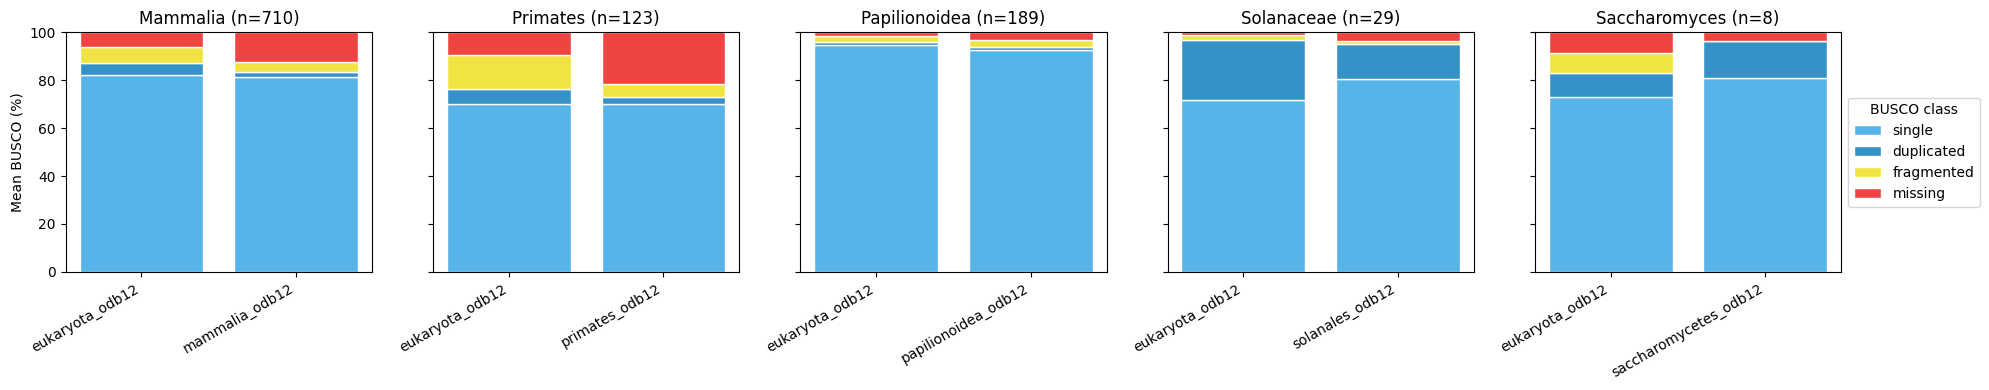

In [12]:
# mean percentage of each BUSCO class (single, duplicated, fragmented, missing) of the eukaryota and of the lineage specific BUSCO, one panel per group
CLASS_COLORS = {"single": "#56B4E9", "duplicated": "#3492C7", "fragmented": "#F0E442", "missing": "#F04442"}
stack = busco_long[busco_long["busco_class"] != "complete"].assign(group=lambda d: d["lineage"])
mean_pct = stack.groupby(["group", "busco_db", "busco_class"])["percentage"].mean()

fig, axes = plt.subplots(1, len(groups_in_table), figsize=(4 * len(groups_in_table), 4), sharey=True, squeeze=False)
axes = axes[0]

for ax, group in zip(axes, groups_in_table):
    dbs = [GENERIC, LINEAGE[group]]
    bottom = np.zeros(len(dbs))
    for cls, color in CLASS_COLORS.items():
        vals = np.array([mean_pct.get((group, db, cls), 0.0) for db in dbs])
        ax.bar(range(len(dbs)), vals, bottom=bottom, color=color, edgecolor="white", label=cls)
        bottom += vals
    ax.set_xticks(range(len(dbs)))
    ax.set_xticklabels(dbs, rotation=30, ha="right")
    ax.set_ylim(0, 100)
    ax.set_title(f"{group} (n={comparison[comparison['group'] == group].shape[0]})")

axes[0].set_ylabel("Mean BUSCO (%)")
axes[-1].legend(title="BUSCO class", loc="center left", bbox_to_anchor=(1, 0.5))
fig.tight_layout()
save_figure(fig, "busco_classes_by_group")
plt.show()